# 01 · ¿Cuánta gente vive en Magdalena de Kino?

Antes de contar a los que llegan hay que contar a los que ya están. Este notebook arma la serie censal oficial de Magdalena con los microdatos por localidad del INEGI (ITER) de 2000, 2005, 2010 y 2020, y la proyección de CONAPO para 2025-2040.

**Decisión metodológica:** el denominador correcto para comparar con la afluencia de las fiestas es la **cabecera** (la localidad Magdalena de Kino, clave 0001), no el municipio: los visitantes llegan al pueblo, no a los ranchos.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema
from src import procesamiento as proc

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

## 1. Serie censal homologada

Cada levantamiento nombra distinto sus columnas (`pobtot` vs `p_total`) y codifica distinto las coordenadas. `proc.leer_iter()` homologa todo.

In [2]:
poblacion = proc.serie_poblacion()
magdalena = poblacion[poblacion["municipio"] == "Magdalena"].reset_index(drop=True)
magdalena

,anio,mun,municipio,cabecera,pob_municipio,pob_cabecera,pct_en_cabecera
0,2000,036,Magdalena,MAGDALENA DE KINO,24447,22023,90.084673
1,2005,036,Magdalena,Magdalena de Kino,25500,23101,90.592157
2,2010,036,Magdalena,Magdalena de Kino,29707,26605,89.558017
3,2020,036,Magdalena,Magdalena de Kino,33049,30429,92.072377


In [3]:
cab = magdalena.set_index("anio")["pob_cabecera"]
crec_20_anios = (cab[2020] / cab[2000] - 1) * 100
crec_anual = ((cab[2020] / cab[2000]) ** (1 / 20) - 1) * 100
print(f"Cabecera 2020: {cab[2020]:,} habitantes")
print(f"Crecimiento 2000-2020: {crec_20_anios:.1f}% ({crec_anual:.2f}% anual compuesto)")
print(f"Proporción del municipio que vive en la cabecera: {magdalena['pct_en_cabecera'].min():.1f}%-{magdalena['pct_en_cabecera'].max():.1f}%")

Cabecera 2020: 30,429 habitantes
Crecimiento 2000-2020: 38.2% (1.63% anual compuesto)
Proporción del municipio que vive en la cabecera: 89.6%-92.1%


## 2. Corrección a fuentes secundarias

En la fase documental tomamos la serie de Citypopulation.de. Contra los microdatos del INEGI, tres de los cuatro años no coinciden. **La cifra de 2020 sí cuadra**, que es la que sostiene el argumento principal.

In [4]:
citypopulation = pd.Series({2000: 22156, 2005: 23419, 2010: 26659, 2020: 30429}, name="citypopulation")
comparacion = pd.concat([cab.rename("inegi_iter"), citypopulation], axis=1)
comparacion["diferencia"] = comparacion["citypopulation"] - comparacion["inegi_iter"]
comparacion

,inegi_iter,citypopulation,diferencia
2000,22023,22156,133
2005,23101,23419,318
2010,26605,26659,54
2020,30429,30429,0


## 3. Proyección 2025-2040 (CONAPO vía COESPO Sonora)

Extraída del PDF oficial con `pdfplumber`. Es una **proyección municipal**, no una medición, y no trae dato de la cabecera. Para estimar la cabecera en 2025 aplicamos la proporción observada en 2020 (92.1%).

La Encuesta Intercensal 2025 del INEGI publicó resultados estatales el 22 de septiembre de 2026, pero al cierre de este notebook no se localizó el desglose de Magdalena.

In [5]:
proyeccion = proc.leer_proyeccion_coespo()
proporcion_2020 = magdalena.set_index("anio").loc[2020, "pct_en_cabecera"] / 100
proyeccion["cabecera_estimada"] = (proyeccion["pob_municipio"] * proporcion_2020).round()
proyeccion

,anio,pob_estado,pct_estatal,pob_municipio,mujeres,hombres,cabecera_estimada
0,2025,3140762,1.14,35668,17821,17847,32840.0
1,2030,3266041,1.15,37458,18662,18796,34488.0
2,2035,3367573,1.16,38985,19385,19600,35894.0
3,2040,3451421,1.17,40314,19974,20340,37118.0


## 4. Vivienda: ¿dónde duerme el pueblo y dónde podría dormir la visita?

El censo 2020 cuenta viviendas deshabitadas y de **uso temporal** (casas que se ocupan solo algunos días del año). No sabemos cuántas se usan en octubre, pero dimensionan el colchón habitacional del pueblo.

In [6]:
vivienda = proc.vivienda_magdalena()
vivienda

,anio,pobtot,vivtot,viv_habitadas,viv_deshabitadas,viv_uso_temporal,hab_por_vivienda
0,2010,26605,8960,7048,1201,708,3.774830
1,2020,30429,11178,9068,1407,701,3.355646


## 5. Figura: el pueblo crece despacio

Esta es la línea base contra la que se comparará la afluencia de las fiestas en el notebook 03.

Interactiva: outputs/figuras/01_poblacion_magdalena.html


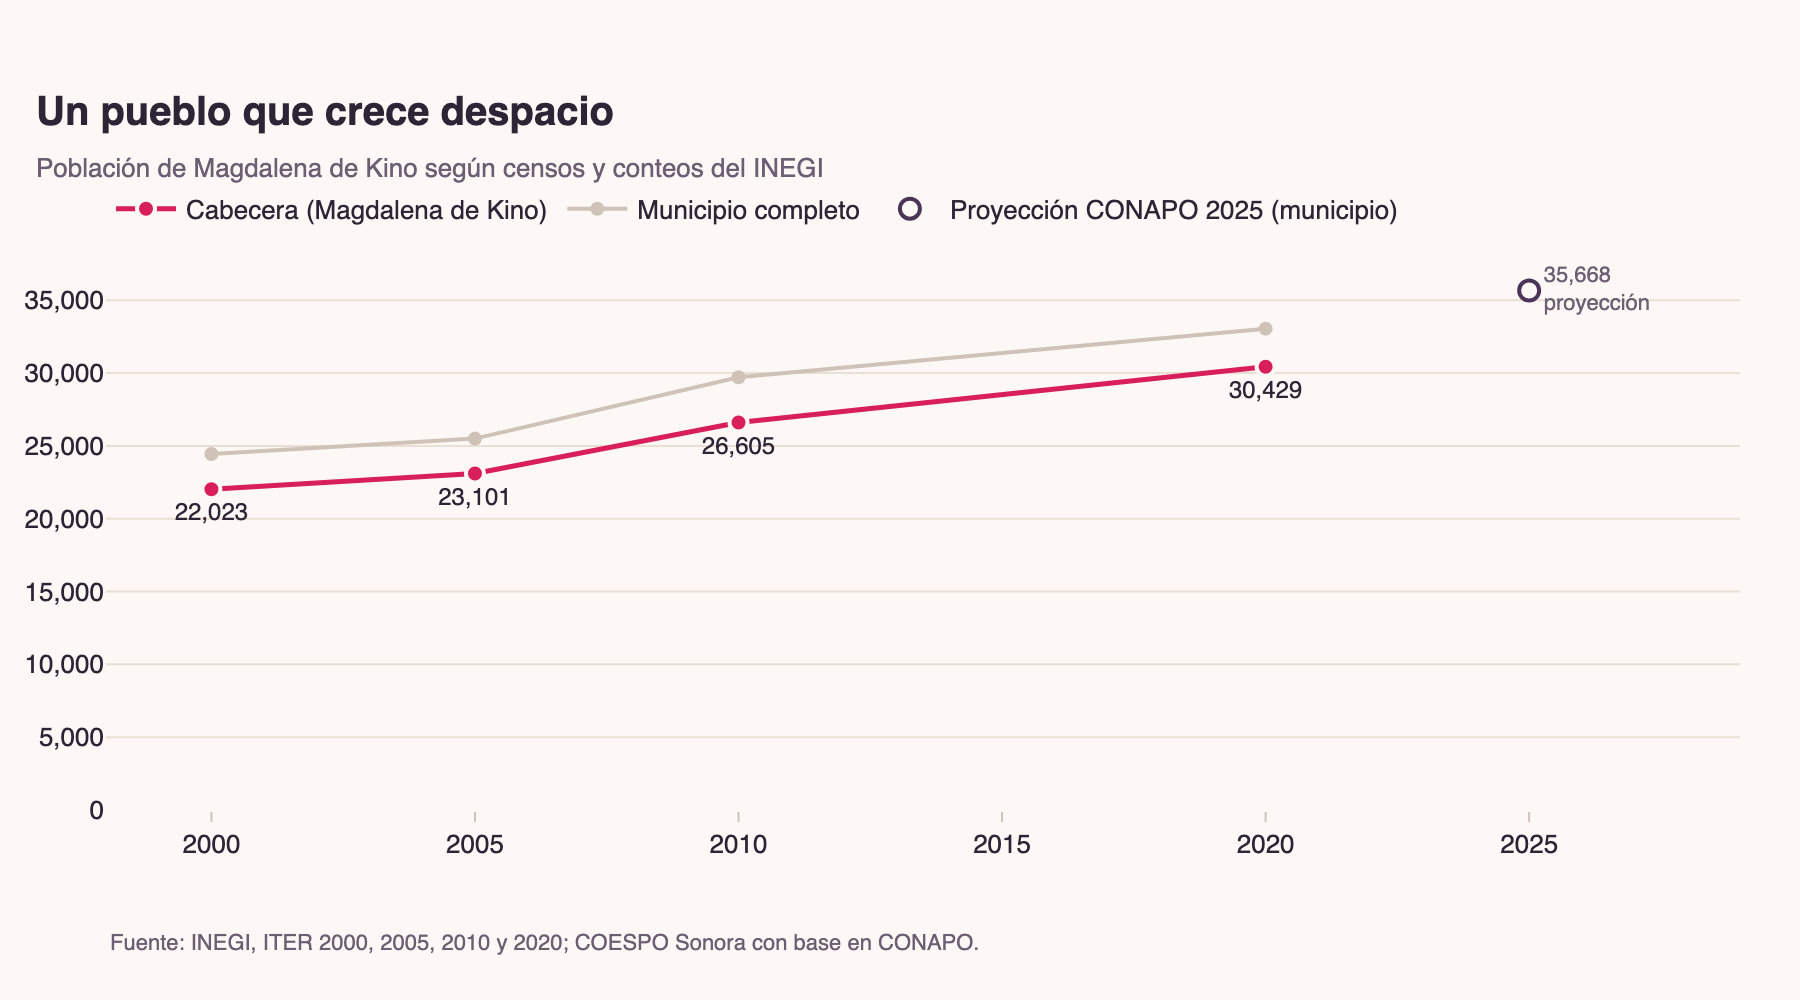

In [7]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=magdalena["anio"], y=magdalena["pob_cabecera"], mode="lines+markers+text",
    name="Cabecera (Magdalena de Kino)", line=dict(color=tema.PROTAGONISTA, width=2.5),
    marker=dict(size=9, line=dict(color=tema.FONDO, width=2)),
    text=[f"{v:,}" for v in magdalena["pob_cabecera"]], textposition="bottom center",
    textfont=dict(color=tema.TEXTO, size=12),
    hovertemplate="<b>%{x}</b><br>Cabecera: %{y:,} habitantes<extra></extra>",
))
fig.add_trace(go.Scatter(
    x=magdalena["anio"], y=magdalena["pob_municipio"], mode="lines+markers",
    name="Municipio completo", line=dict(color=tema.NEUTRO, width=2), marker=dict(size=7),
    hovertemplate="<b>%{x}</b><br>Municipio: %{y:,} habitantes<extra></extra>",
))
p25 = proyeccion[proyeccion["anio"] == 2025].iloc[0]
fig.add_trace(go.Scatter(
    x=[2025], y=[p25["pob_municipio"]], mode="markers+text", name="Proyección CONAPO 2025 (municipio)",
    marker=dict(size=10, symbol="circle-open", color=tema.CONTORNO, line=dict(width=2)),
    text=[f"{p25['pob_municipio']:,.0f}<br>proyección"], textposition="middle right",
    textfont=dict(color=tema.TEXTO_SUAVE, size=11),
    hovertemplate="<b>2025 (proyección)</b><br>Municipio: %{y:,}<extra></extra>",
))
fig.update_layout(
    title=tema.titulo("Un pueblo que crece despacio", "Población de Magdalena de Kino según censos y conteos del INEGI"),
    yaxis=dict(title=None, rangemode="tozero", tickformat=","),
    xaxis=dict(tickvals=[2000, 2005, 2010, 2015, 2020, 2025], range=[1998, 2029]),
    height=500,
)
tema.nota_fuente(fig, "Fuente: INEGI, ITER 2000, 2005, 2010 y 2020; COESPO Sonora con base en CONAPO.")
tema.mostrar(fig, "01_poblacion_magdalena")

**Lectura:** la cabecera pasó de 22,023 a 30,429 habitantes en veinte años, un ritmo de alrededor de 1.6% anual. Es una línea suave, sin sobresaltos. Cualquier pico que veamos en octubre no viene de la demografía del pueblo.

In [8]:
config.DIR_PROCESSED.mkdir(parents=True, exist_ok=True)
poblacion.to_csv(config.DIR_PROCESSED / "poblacion_censal.csv", index=False)
proyeccion.to_csv(config.DIR_PROCESSED / "proyeccion_coespo_magdalena.csv", index=False)
vivienda.to_csv(config.DIR_PROCESSED / "vivienda_magdalena.csv", index=False)

## Conclusiones

- **30,429 habitantes** en la cabecera (Censo 2020). Es el denominador de todo el proyecto.
- Las cifras de Citypopulation para 2000, 2005 y 2010 difieren de los microdatos del INEGI; en adelante usamos solo el ITER.
- El 92% del municipio vive en la cabecera, así que usar el municipio en lugar del pueblo cambiaría poco el resultado.
- En 2020 el pueblo tenía 701 viviendas de uso temporal y 1,407 deshabitadas.